# Heart Attack Prediction - Classification Project

In this project I use a patient's medical information to predict whether they have a **low (0)** or **high (1)** chance of a heart attack.

Models used: **KNN**, **Logistic Regression**, **Decision Tree** and **SVM**.

Steps:
1. Import libraries
2. Load the data
3. Clean the data
4. Explore the data (EDA)
5. Preprocessing (LabelEncoder, train/test split, StandardScaler)
6. Train the models
7. Compare the models
8. Conclusion

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## 2. Load the data

The columns are:

| Column | Meaning |
|---|---|
| age | Age |
| sex | Sex (1 = male, 0 = female) |
| cp | Chest pain type |
| trtbps | Resting blood pressure |
| chol | Cholesterol |
| fbs | Fasting blood sugar / diabetes (1 = yes, 0 = no) |
| restecg | Resting ECG result (0 = normal, 1 = abnormal ST, 2 = left ventricle enlarged) |
| thalachh | Maximum heart rate |
| exng | Chest pain starts with activity (1 = yes, 0 = no) |
| oldpeak | ST depression during exercise |
| slp | Slope of the ST segment |
| caa | Number of major vessels (0 to 3) |
| thall | Thallium test result |
| output | **Target**: chance of heart attack (0 = low, 1 = high) |

In [2]:
df = pd.read_csv("data/heart.csv")
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trtbps    303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalachh  303 non-null    int64  
 8   exng      303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slp       303 non-null    int64  
 11  caa       303 non-null    int64  
 12  thall     303 non-null    int64  
 13  output    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [4]:
df.describe()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## 3. Clean the data

Before training, I check for:
- **missing values**
- **duplicate rows** (a duplicate could end up in both train and test and make the result look better than it is)
- **wrong values**: `caa` should be 0 to 3 and `thall` should be 1 to 3

In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

Duplicate rows: 1


In [6]:
print("caa values:", df["caa"].value_counts().sort_index().to_dict())
print("thall values:", df["thall"].value_counts().sort_index().to_dict())

caa values: {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thall values: {0: 2, 1: 18, 2: 166, 3: 117}


There are no missing values, but there is **1 duplicate row**. Also `caa = 4` and `thall = 0` are not valid values.

- I drop the duplicate.
- For the wrong values I replace them with the **most common value (mode)** of that column. There are only a few of them, so this is better than deleting the rows.

In [7]:
df = df.drop_duplicates()

df["caa"] = df["caa"].replace(4, df["caa"].mode()[0])
df["thall"] = df["thall"].replace(0, df["thall"].mode()[0])

print("New shape:", df.shape)
print("caa values:", df["caa"].value_counts().sort_index().to_dict())
print("thall values:", df["thall"].value_counts().sort_index().to_dict())

New shape: (302, 14)
caa values: {0: 179, 1: 65, 2: 38, 3: 20}
thall values: {1: 18, 2: 167, 3: 117}


## 4. Explore the data (EDA)

### Target balance
First I check whether the two classes have a similar number of patients. If one class is much bigger, accuracy alone would not be a good metric.

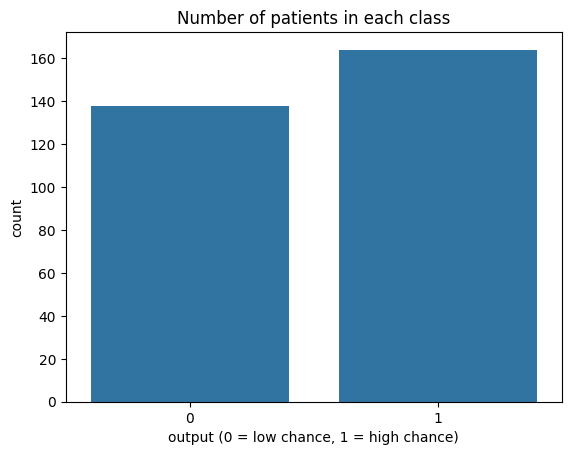

output
1    164
0    138
Name: count, dtype: int64


In [8]:
sns.countplot(x="output", data=df)
plt.title("Number of patients in each class")
plt.xlabel("output (0 = low chance, 1 = high chance)")
plt.show()

print(df["output"].value_counts())

The classes are fairly balanced (about 54% / 46%), so accuracy is a good main metric here.

### Categorical features vs target

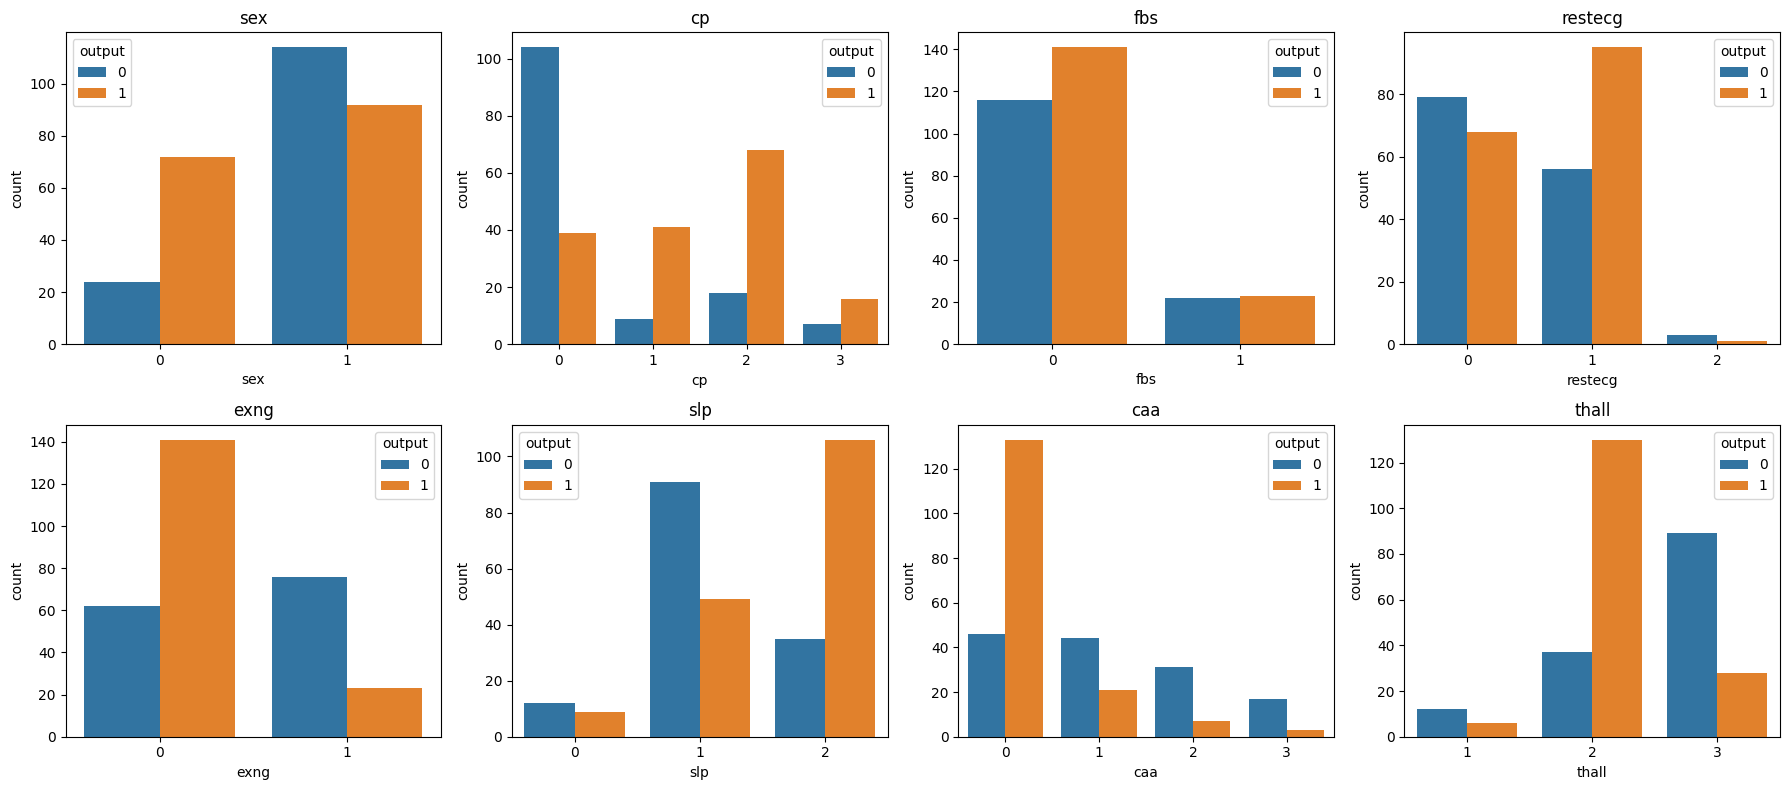

In [9]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exng", "slp", "caa", "thall"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for col, ax in zip(cat_cols, axes.flatten()):
    sns.countplot(x=col, hue="output", data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Some features clearly separate the two classes:
- **cp**: patients with chest pain type 0 are mostly in class 0. Types 1, 2 and 3 are mostly class 1.
- **exng**: patients with exng = 1 are mostly class 0.
- **caa**: caa = 0 is mostly class 1.
- **thall**: thall = 2 is mostly class 1 and thall = 3 is mostly class 0.
- **fbs** looks almost the same for both classes, so it is probably not very useful.

### Numeric features vs target

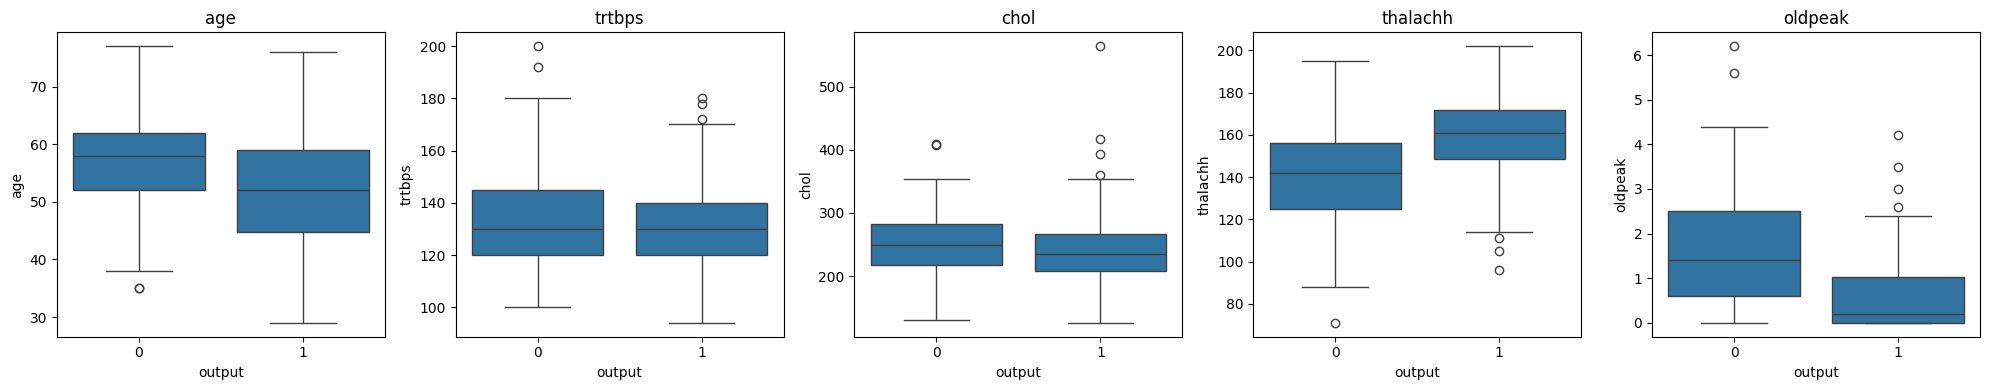

In [10]:
num_cols = ["age", "trtbps", "chol", "thalachh", "oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for col, ax in zip(num_cols, axes):
    sns.boxplot(x="output", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

- **thalachh** (max heart rate) is higher in class 1.
- **oldpeak** is lower in class 1.
- **trtbps** and **chol** are almost the same in both classes.

### Correlation

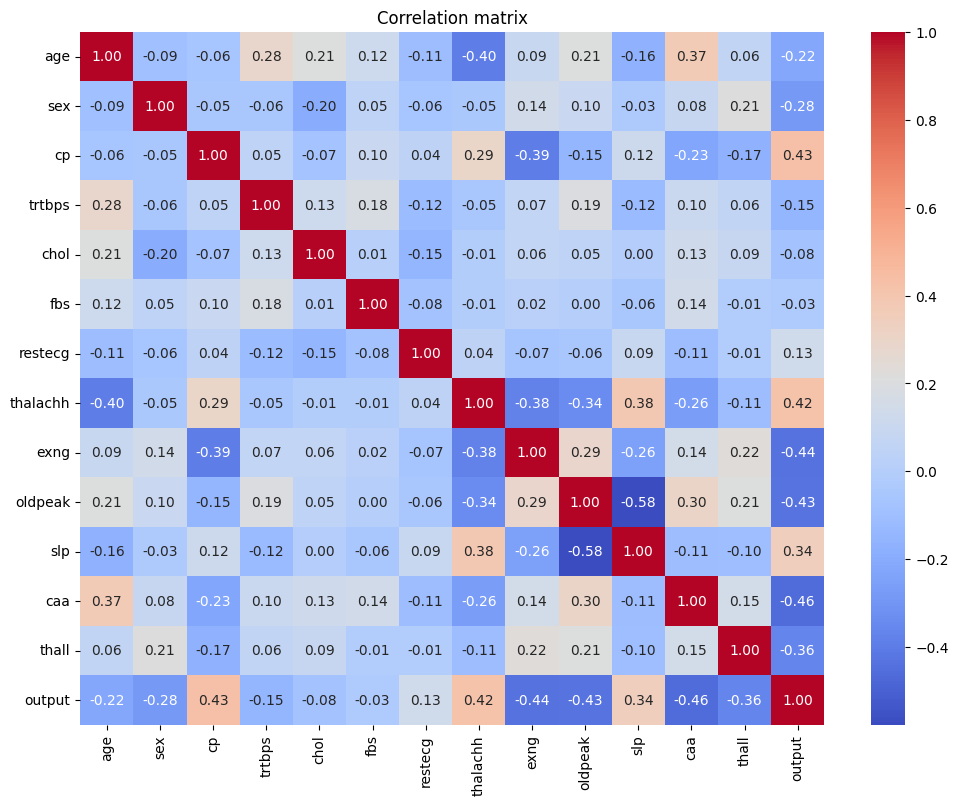

In [11]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

The features most correlated with `output` are `cp`, `thalachh`, `exng`, `oldpeak`, `caa` and `thall`. This matches what I saw in the plots above.

## 5. Preprocessing

### 5.1 LabelEncoder
The categorical columns are already numbers, but I use **LabelEncoder** to make sure each one is coded as 0, 1, 2, ... with no gaps. For example, `thall` is 1, 2, 3 and becomes 0, 1, 2.

In [12]:
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

df[cat_cols].head()

,sex,cp,fbs,restecg,exng,slp,caa,thall
0,1,3,1,0,0,0,0,0
1,1,2,0,1,0,0,0,1
2,0,1,0,0,0,2,0,1
3,1,1,0,1,0,2,0,1
4,0,0,0,1,1,2,0,1


### 5.2 Split X and y, then train and test
- **X** = all features, **y** = `output`
- 80% of the data is used for training and 20% for testing.
- `stratify=y` keeps the same class ratio in train and test.
- `random_state=42` makes the result the same every time I run it.

In [13]:
X = df.drop("output", axis=1)
y = df["output"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (241, 13)
Test: (61, 13)


### 5.3 StandardScaler
KNN and SVM use distances, so a feature with big numbers (like `chol` around 250) would matter much more than one with small numbers (like `oldpeak` around 1). **StandardScaler** changes every feature to mean 0 and standard deviation 1, so they are all on the same scale.

I fit the scaler **only on the training data** and then use it to transform the test data. If I fit it on all the data, information from the test set would leak into training.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Train the models

To avoid repeating the same code, I write a small function. It trains a model, prints accuracy and the classification report, and shows the confusion matrix.

In [15]:
results = {}

def evaluate(name, model):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print(f"{name} - Test accuracy: {acc:.3f}\n")
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap="Blues")
    plt.title(name)
    plt.show()

### 6.1 KNN

The most important parameter in KNN is **k** (the number of neighbours).
- A small k can overfit (it follows noise).
- A large k can underfit (it becomes too simple).

I try k from 1 to 30 and choose the best one with **5-fold cross validation on the training data**. I don't use the test data to choose k, because then the test score would no longer be a fair check.

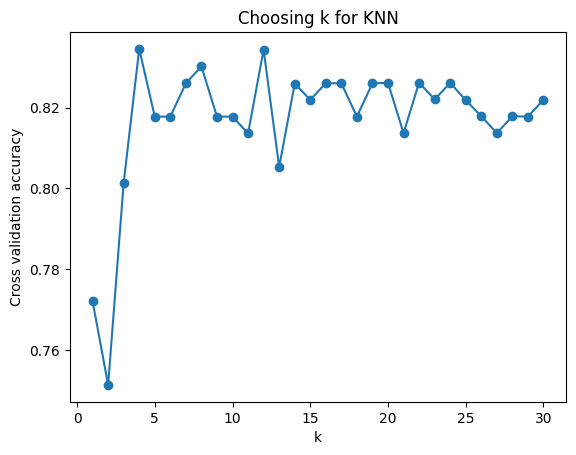

Best k: 4


In [16]:
k_values = range(1, 31)
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(knn, X_train_scaled, y_train, cv=5).mean())

best_k = k_values[np.argmax(cv_scores)]

plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Cross validation accuracy")
plt.title("Choosing k for KNN")
plt.show()

print("Best k:", best_k)

KNN - Test accuracy: 0.770

              precision    recall  f1-score   support

           0       0.72      0.82      0.77        28
           1       0.83      0.73      0.77        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.78      0.77      0.77        61



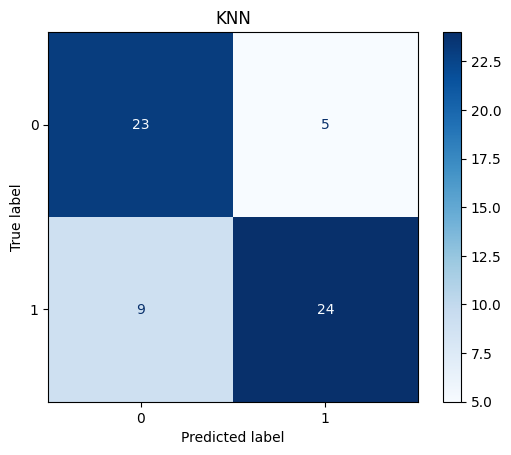

In [17]:
evaluate("KNN", KNeighborsClassifier(n_neighbors=best_k))

### 6.2 Logistic Regression
Logistic Regression is a simple linear model. It gives the probability of class 1, and if that probability is above 0.5 the prediction is 1.

Logistic Regression - Test accuracy: 0.820

              precision    recall  f1-score   support

           0       0.84      0.75      0.79        28
           1       0.81      0.88      0.84        33

    accuracy                           0.82        61
   macro avg       0.82      0.81      0.82        61
weighted avg       0.82      0.82      0.82        61



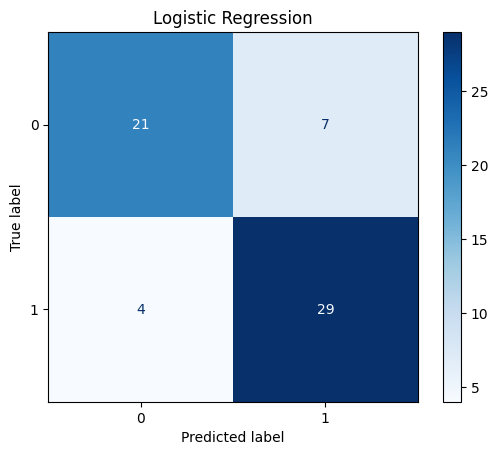

In [18]:
evaluate("Logistic Regression", LogisticRegression(max_iter=1000))

One good thing about Logistic Regression is that we can look at its **coefficients**. A positive coefficient pushes toward class 1 (high chance), and a negative one pushes toward class 0. Because the data is scaled, the sizes can be compared.

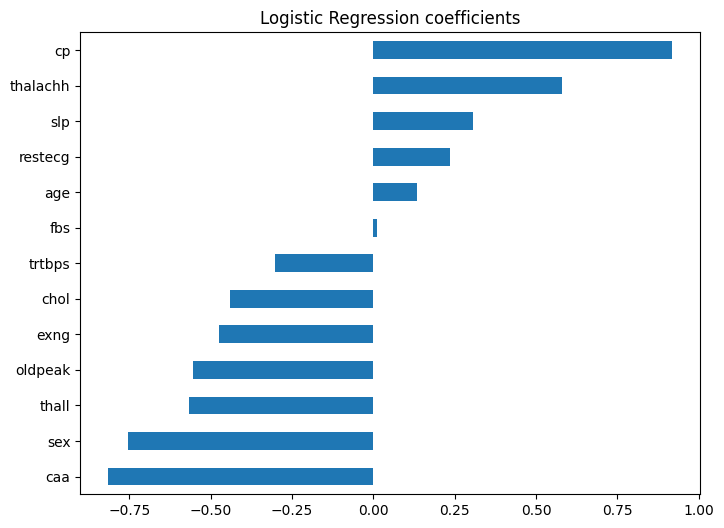

In [19]:
log_model = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
coef = pd.Series(log_model.coef_[0], index=X.columns).sort_values()

coef.plot(kind="barh", figsize=(8, 6))
plt.title("Logistic Regression coefficients")
plt.show()

### 6.3 Decision Tree
A decision tree with no limit keeps splitting until it memorises the training data (overfitting). So I limit its depth with **max_depth** and choose the best depth with cross validation, the same way as for k in KNN.

(Decision trees don't actually need scaling, but using the scaled data does not change the result.)

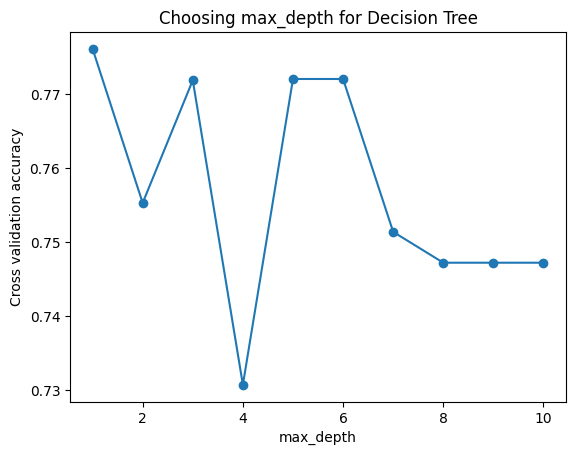

Best max_depth: 1


In [20]:
depths = range(1, 11)
cv_scores = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_scores.append(cross_val_score(tree, X_train_scaled, y_train, cv=5).mean())

best_depth = depths[np.argmax(cv_scores)]

plt.plot(depths, cv_scores, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Cross validation accuracy")
plt.title("Choosing max_depth for Decision Tree")
plt.show()

print("Best max_depth:", best_depth)

Decision Tree - Test accuracy: 0.689

              precision    recall  f1-score   support

           0       0.66      0.68      0.67        28
           1       0.72      0.70      0.71        33

    accuracy                           0.69        61
   macro avg       0.69      0.69      0.69        61
weighted avg       0.69      0.69      0.69        61



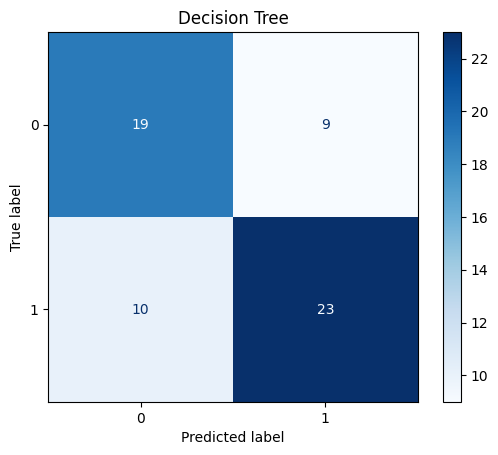

In [21]:
evaluate("Decision Tree", DecisionTreeClassifier(max_depth=best_depth, random_state=42))

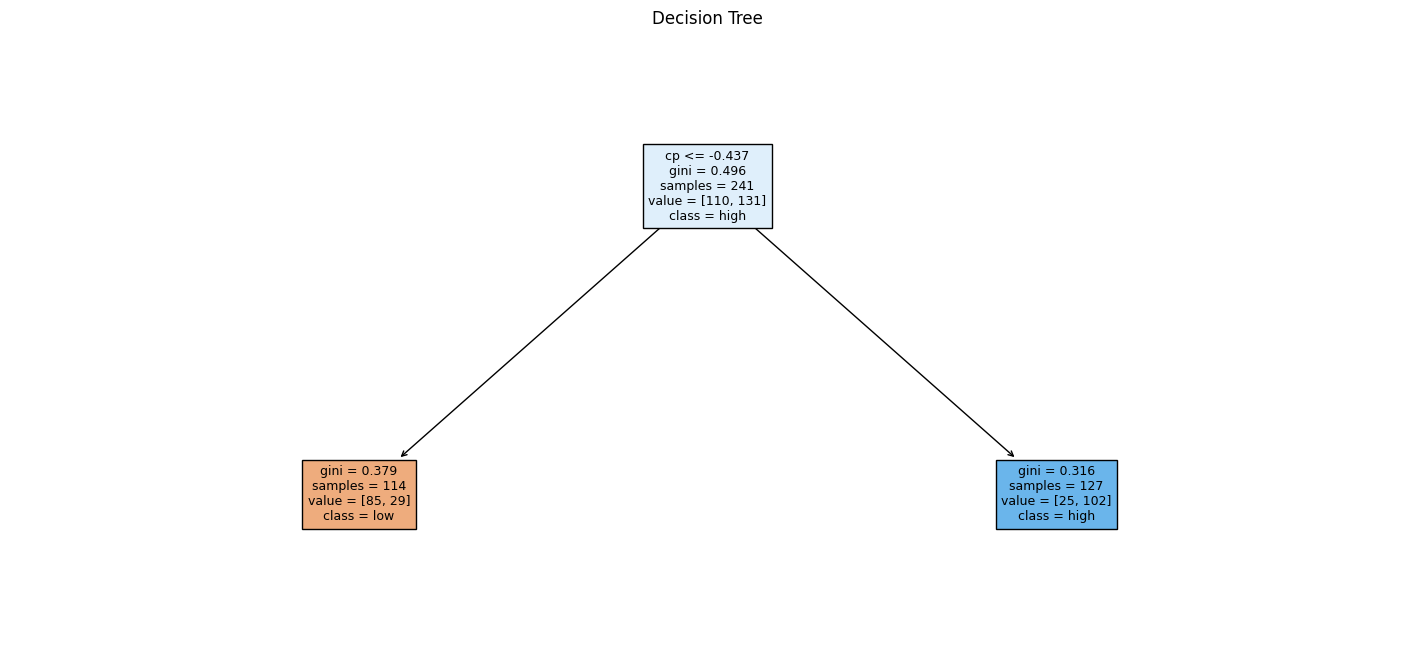

In [22]:
tree_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train_scaled, y_train)

plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=X.columns, class_names=["low", "high"], filled=True, fontsize=9)
plt.title("Decision Tree")
plt.show()


Cross validation picked **max_depth = 1**, so the tree asks only one question, about `cp` (chest pain type): if `cp` is 0 the prediction is **low**, otherwise it is **high**. (The value -0.437 in the plot is `cp` after scaling.) Looking at the plot of depths, the scores for all depths are very close (about 0.73 to 0.78). This means deeper trees did not learn anything extra that works on new data; they mostly started to overfit. A single decision tree is not very strong on this dataset.


### 6.4 SVM
SVM finds the boundary that separates the two classes with the biggest margin. I try two kernels:
- **linear**: a straight boundary
- **rbf**: a curved boundary

In [23]:
for kernel in ["linear", "rbf"]:
    score = cross_val_score(SVC(kernel=kernel), X_train_scaled, y_train, cv=5).mean()
    print(f"{kernel}: cross validation accuracy = {score:.3f}")

linear: cross validation accuracy = 0.830
rbf: cross validation accuracy = 0.822


SVM (linear) - Test accuracy: 0.836

              precision    recall  f1-score   support

           0       0.95      0.68      0.79        28
           1       0.78      0.97      0.86        33

    accuracy                           0.84        61
   macro avg       0.87      0.82      0.83        61
weighted avg       0.86      0.84      0.83        61



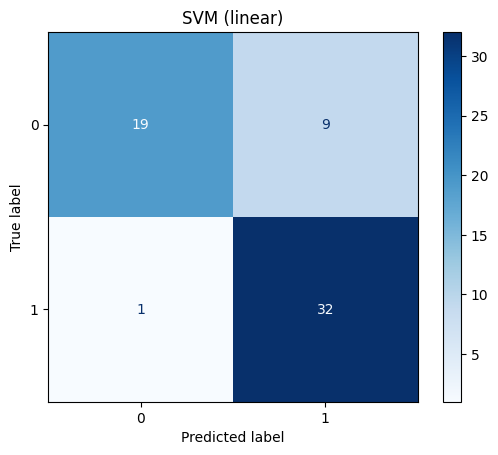

SVM (rbf) - Test accuracy: 0.836

              precision    recall  f1-score   support

           0       0.91      0.71      0.80        28
           1       0.79      0.94      0.86        33

    accuracy                           0.84        61
   macro avg       0.85      0.83      0.83        61
weighted avg       0.85      0.84      0.83        61



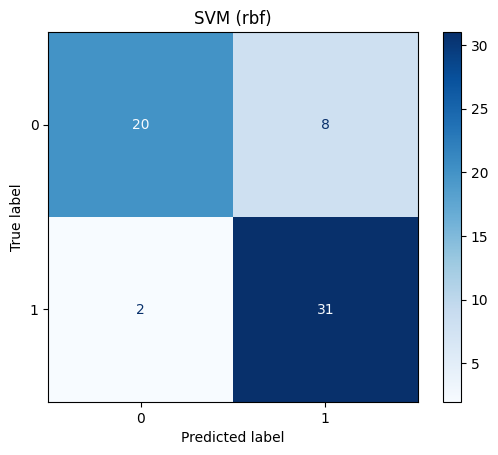

In [24]:
evaluate("SVM (linear)", SVC(kernel="linear"))
evaluate("SVM (rbf)", SVC(kernel="rbf"))

## 7. Compare the models

In [25]:
results_df = pd.DataFrame(list(results.items()), columns=["Model", "Test accuracy"])
results_df = results_df.sort_values("Test accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,Test accuracy
0,SVM (linear),0.836066
1,SVM (rbf),0.836066
2,Logistic Regression,0.819672
3,KNN,0.770492
4,Decision Tree,0.688525


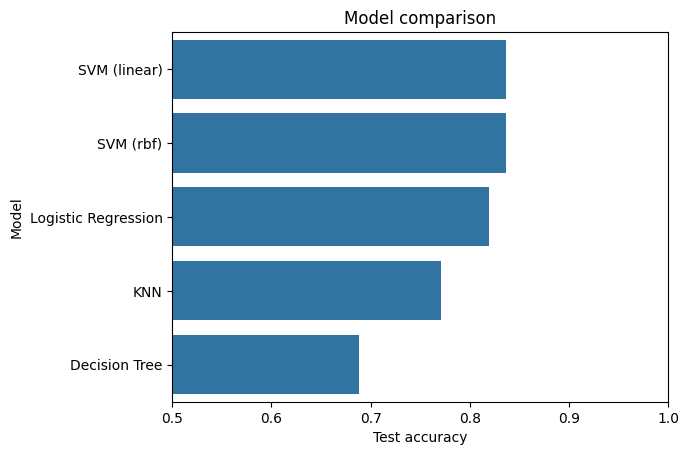

In [26]:
sns.barplot(x="Test accuracy", y="Model", data=results_df)
plt.xlim(0.5, 1)
plt.title("Model comparison")
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Conclusion

| Model | Test accuracy |
|---|---|
| SVM (linear) | 0.84 |
| SVM (rbf) | 0.84 |
| Logistic Regression | 0.82 |
| KNN (k = 4) | 0.77 |
| Decision Tree (max_depth = 1) | 0.69 |

- **SVM was the best model**, with about 84% accuracy on the test data. The linear and rbf kernels gave the same accuracy.
- **Logistic Regression was very close** (82%). Because the linear models (Logistic Regression and linear SVM) work this well, the two classes can be separated quite well by a straight boundary.
- **KNN** was a bit weaker (77%).
- The **Decision Tree** was the weakest (69%). One tree overfits easily on a small dataset like this.
- For SVM (linear), the **recall for class 1 is 0.97**: almost every high-chance patient in the test set was found. In a medical problem this is important, because missing a high-chance patient is worse than a false alarm.
- The most useful features were `cp`, `thalachh`, `exng`, `oldpeak`, `caa` and `thall`. `fbs` and `chol` helped very little.

**Note:** the dataset is small (302 patients, 61 in the test set), so one patient changes the test accuracy by about 1.6%. Differences of 1 to 2% between models are not really meaningful.
